## **[실습 2] scikit-learn을 활용한 Linear Regression**

### **1. 데이터 생성하기**

**Q1. 200개의 0~30 사이의 랜덤한 데이터를 생성한다**

그리고 이 데이터를 X라는 변수에 저장한다.

- [HINT] : np.random.randint()

In [21]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
np.random.seed(42) # 재현성을 위함
X = np.random.randint(0, 31, 200)
print(X[:10])

[ 6 19 28 14 10  7 28 20  6 25]


**Q2. X에 정규분포적 샘플을 더한다.**

- X 에 살짝 노이즈를 넣자
  - '선형 관계 + 오차' 형태의 데이터로 만든다.
그리고 이 데이터를 y라는 변수에 저장한다.

그리고 데이터를 y라는 변수에 저장한다.
- [HINT] : np.random.normal()

In [18]:
y = X + np.random.normal(0, 3, 200) # mean = 0, st.dev = 3
print(f"x = {X[:10]}")
print(f"y = {y[:10]}")

x = [ 6 19 28 14 10  7 28 20  6 25]
y = [ 5.95073131 22.56517982 35.58079728 12.40739368  8.53168167 10.13248263
 30.04567447 25.54012198  7.75178456 23.92212373]


### **2. 데이터 시각화하기**

**Q1. X와 y를 scatterplot으로 시각화한다.**

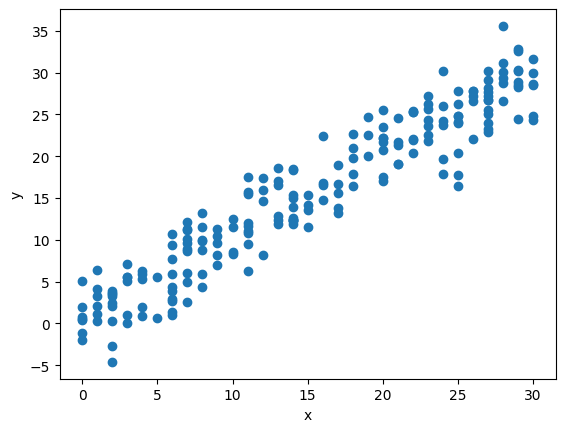

In [20]:
plt.scatter(X, y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### **3. Train, Test 데이터 분할하기**

**Q1.X와 y를 학습용 데이터와 테스트용 데이터로 분리한다.**
- 학습 : 테스트 데이터의 비율은 7 : 3 으로 한다.

**변수명은 다음과 같이 지정한다.**
- X_train : 학습 데이터의 특성
- X_test : 테스트 데이터의 특성
- y_train : 학습 데이터의 라벨
- y_test : 테스트 데이터의 라벨

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

(140,) (60,)


### **4.Train과 Test 데이터 시각화하기**

**Q1.학습 데이터와 테스트 데이터를 다른 색상으로 scatterplot에 시각화해본다.**

test데이터는 test라는 라벨을 달아주고, train데이터는 train이라는 라벨을 달아준다.

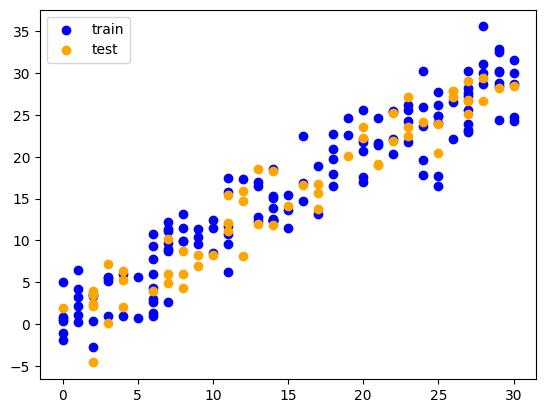

In [28]:
plt.scatter(X_train, y_train, color="blue", label="train")
plt.scatter(X_test, y_test, color="orange", label="test")
plt.legend()
plt.show()

### **5. 모델 생성, 학습**

**Q1. scikit-learn의 LinearRegression() 모델을 사용해서 학습 데이터로 학습시킨다.**

[HINT] : 현재 데이터가 scikit-learn의 모델이 학습하지 못하는 형태일 것이다 (1차원)
  - 에러 메세지를 잘 읽어보면 답이 나온다.

In [30]:
model = LinearRegression()
model.fit(X_train.reshape(-1, 1), y_train) # (200, ) -> 1D array ==> 2D로 변

LinearRegression()

**Q2. Linear Regression 모델이 학습한 coefficient와 intercept를 출력한다.**

In [32]:
print(f"coefficient = {model.coef_}")
print(f"intercept = {model.intercept_}")

coefficient = [0.96523404]
intercept = 1.059183082922127


### **6. 모델 테스트**

**Q1. 학습된 모델을 활용하여 테스트 데이터에 대한 예측 결과를 낸다.**

결과는 y_pred라는 변수에 저장한다.

In [36]:
y_pred = model.predict(X_test.reshape(-1, 1))
print(y_pred)

[21.32909792 20.36386388  1.05918308  8.7810554  12.64199156  7.81582136
  8.7810554  11.67675752  2.98965116 14.57245964 13.6072256   4.92011924
 22.29433195 11.67675752 13.6072256   4.92011924  4.92011924  9.74628944
  2.98965116 25.19003407 24.22480003  3.9548852   2.98965116  9.74628944
 27.12050215  8.7810554  16.50292772 17.46816176 27.12050215 12.64199156
 25.19003407 23.25956599  2.98965116 14.57245964 26.15526811  3.9548852
  6.85058732 23.25956599 22.29433195 27.12050215 28.08573619 30.01620427
 26.15526811 11.67675752 23.25956599 12.64199156 20.36386388  2.98965116
 10.71152348 17.46816176 29.05097023 26.15526811  7.81582136 27.12050215
 15.53769368 19.39862984  7.81582136 17.46816176 21.32909792 28.08573619]


**Q2. 모델을 테스트 데이터를 활용해서 테스트한다.**

MAE, MSE, RMSE, 그리고 R2-score를 구하고, 출력해본다.

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)\

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2-score: {r2:.4f}")

MAE: 2.0204
MSE: 6.3031
RMSE: 2.5106
R2-score: 0.9267


### **7. Line of Best Fit 시각화하기**

**Q1. Line of Best Fit을 위의 scatterplot에 그려보자.**
- Line of Best Fit은 빨간색 파선으로, label="Line of Best Fit"이라고 작성한다.
- 그래프의 title을 "Linear Regression"으로 설정한다.

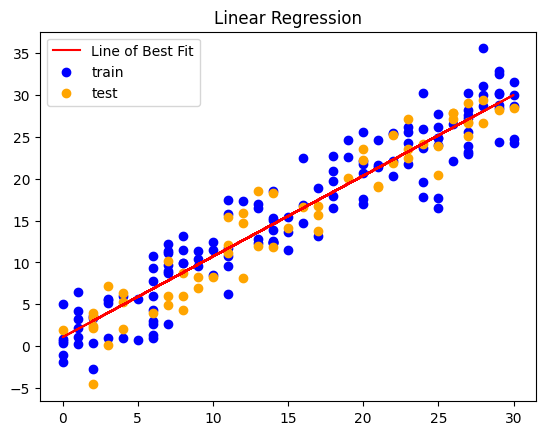

In [44]:
plt.plot(X_test, y_pred, color="red", label="Line of Best Fit")
plt.scatter(X_train, y_train, color="blue", label="train")
plt.scatter(X_test, y_test, color="orange", label="test")
plt.legend()
plt.title("Linear Regression")
plt.show()